# Task 1: Local Search & Propositional Logic (N-Queens Problem)
**Course:** Introduction to Artificial Intelligence (503043)  
**Institution:** Faculty of Information Technology, Ton Duc Thang University (TDTU)  
**Author:** Student Group  

---

## Table of Contents
1. **Propositional Logic Formulation & CNF Clause Generation (Req 1)**
2. **Solving with Glucose3 SAT Solver (PySAT) for $N \ge 4$ (Req 2)**
3. **Min-Conflicts Local Search & Proposed Variable Selection Heuristics (Req 3)**
4. **Performance Benchmark & Comparative Evaluation**

### 1. Propositional Logic Formulation & CNF Clause Generation (Req 1 - 1.0 pt)

- **Boolean Propositional Variables:** Let $X_{r, c} \in \{True, False\}$ for $0 \le r, c < N$, representing whether a queen is placed at square $(r, c)$.
- **DIMACS Integer Encoding:** Variable indices are mapped to positive integers:
  $$\text{var\_id}(r, c) = r \cdot N + c + 1 \in [1, N^2]$$
- **Constraint Groups:**
  1. **Row Constraints (Exactly-One):**
     - At-Least-One (ALO): $\bigvee_{c=0}^{N-1} X_{r, c}$
     - At-Most-One (AMO): $\bigwedge_{0 \le c_1 < c_2 < N} (\neg X_{r, c_1} \lor \neg X_{r, c_2})$
  2. **Column Constraints (Exactly-One):**
     - At-Least-One (ALO): $\bigvee_{r=0}^{N-1} X_{r, c}$
     - At-Most-One (AMO): $\bigwedge_{0 \le r_1 < r_2 < N} (\neg X_{r_1, c} \lor \neg X_{r_2, c})$
  3. **Main Diagonal Constraints (AMO):** At most one queen on each diagonal $r - c = k$ for $-(N - 1) \le k \le N - 1$.
  4. **Anti Diagonal Constraints (AMO):** At most one queen on each diagonal $r + c = k$ for $0 \le k \le 2N - 2$.
- **Theoretical Clause Count Formula:**
  $$\text{Total Clauses} = 2N + N^2(N - 1) + \frac{N(N - 1)(2N - 1)}{3}$$

In [1]:
import sys
import os

# Add parent source directory to sys.path
source_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if source_dir not in sys.path:
    sys.path.insert(0, source_dir)

from task1_nqueens.core.problem import NQueensProblem
from task1_nqueens.core.constraints import ConstraintGenerator
from task1_nqueens.experiments.benchmark import BenchmarkRunner

print("=== VERIFYING CNF CONSTRAINT GENERATOR INTEGRITY ===")
for test_n in [4, 6, 8]:
    prob = NQueensProblem(test_n)
    gen = ConstraintGenerator(prob)
    clauses = gen.generate_all_cnf()
    stats = gen.get_clause_statistics()
    theo = gen.get_theoretical_clause_count()
    print(f"[N = {test_n:2d}] Variables: {stats['variables']:3d} | Generated: {len(clauses):5d} | Theoretical: {theo:5d} | Exact Match: {len(clauses) == theo}")
    print(f"        Breakdown: Row ALO={stats['row_alo']}, Row AMO={stats['row_amo']}, Col ALO={stats['col_alo']}, Col AMO={stats['col_amo']}, Diag AMO={stats['diagonal_amo']}")

# Generate and display CNF clause count breakdown
runner_cnf = BenchmarkRunner()
runner_cnf.plot_cnf_breakdown("cnf_breakdown_task1.png", [4, 6, 8, 12, 16, 20])


=== VERIFYING CNF CONSTRAINT GENERATOR INTEGRITY ===
[N =  4] Variables:  16 | Generated:    84 | Theoretical:    84 | Exact Match: True
        Breakdown: Row ALO=4, Row AMO=24, Col ALO=4, Col AMO=24, Diag AMO=28
[N =  6] Variables:  36 | Generated:   302 | Theoretical:   302 | Exact Match: True
        Breakdown: Row ALO=6, Row AMO=90, Col ALO=6, Col AMO=90, Diag AMO=110
[N =  8] Variables:  64 | Generated:   744 | Theoretical:   744 | Exact Match: True
        Breakdown: Row ALO=8, Row AMO=224, Col ALO=8, Col AMO=224, Diag AMO=280



[Visual] CNF clause breakdown bar chart saved to: C:\Users\Nhi\OneDrive\Documents\AI_final_project\source\task1_nqueens\cnf_breakdown_task1.png


'C:\\Users\\Nhi\\OneDrive\\Documents\\AI_final_project\\source\\task1_nqueens\\cnf_breakdown_task1.png'

### 2. Solving with Glucose3 SAT Solver (PySAT) for $N \ge 4$ (Req 2 - 1.0 pt)

We evaluate the Glucose3 solver from `pysat.solvers` across increasing values of $N \ge 4$ ($N = 4, 8, 12, 16, 20, 24, 28, 32$), recording clause counts and execution time.

In [2]:
from task1_nqueens.solvers.sat_solver import Glucose3SATSolver

sat_solver = Glucose3SATSolver()
sat_results = []
test_sizes_sat = [4, 8, 12, 16, 20, 24, 28, 32]

print("=== GLUCOSE3 SAT SOLVER EXPERIMENT RESULTS (PySAT) ===")
print(f"{'N':>3} | {'Vars (N^2)':>10} | {'CNF Clauses':>12} | {'Time (sec)':>14} | {'Sample Solution (col->row)':<28}")
print("-" * 80)

for test_n in test_sizes_sat:
    res = sat_solver.solve(test_n)
    sat_results.append(res)
    sol_str = str(res.solution[:6]) + "..." if len(res.solution) > 6 else str(res.solution)
    print(f"{test_n:3d} | {test_n**2:10d} | {res.num_clauses:12d} | {res.execution_time:14.6f} | {sol_str:<28}")

# 1. ASCII Visualization for N = 8
print("\n1. ASCII Visualization of N = 8 solution (Glucose3 SAT Solver):")
prob_8 = NQueensProblem(8)
res_8 = sat_solver.solve(8)
prob_8.display(res_8.solution)

# 2. Publication-quality Graphical Chessboard Visualization using Matplotlib
print("2. Graphical Chessboard Visualization of N = 8 solution:")
prob_8.plot_board(res_8.solution, title="N = 8 Queens Solution (Glucose3 SAT Solver)", save_path="nqueens_board_n8.png", show=True)


=== GLUCOSE3 SAT SOLVER EXPERIMENT RESULTS (PySAT) ===
  N | Vars (N^2) |  CNF Clauses |     Time (sec) | Sample Solution (col->row)  
--------------------------------------------------------------------------------
  4 |         16 |           84 |       0.000095 | [1, 3, 0, 2]                
  8 |         64 |          744 |       0.000306 | [7, 1, 3, 0, 6, 4]...       
 12 |        144 |         2620 |       0.000885 | [11, 3, 10, 0, 9, 5]...     
 16 |        256 |         6352 |       0.043059 | [15, 12, 14, 3, 13, 6]...   
 20 |        400 |        12580 |       0.005314 | [19, 10, 6, 17, 14, 16]...  


 24 |        576 |        21944 |       0.201118 | [9, 20, 10, 19, 6, 23]...   


 28 |        784 |        35084 |       0.009063 | [10, 27, 6, 26, 21, 19]...  


 32 |       1024 |        52640 |       0.016220 | [12, 10, 8, 27, 25, 22]...  

1. ASCII Visualization of N = 8 solution (Glucose3 SAT Solver):

--- N-Queens Board (N = 8) ---
Row  0 | .  .  .  Q  .  .  .  . |
Row  1 | .  Q  .  .  .  .  .  . |
Row  2 | .  .  .  .  .  .  Q  . |
Row  3 | .  .  Q  .  .  .  .  . |
Row  4 | .  .  .  .  .  Q  .  . |
Row  5 | .  .  .  .  .  .  .  Q |
Row  6 | .  .  .  .  Q  .  .  . |
Row  7 | Q  .  .  .  .  .  .  . |
       ------------------------
 Col     0  1  2  3  4  5  6  7

2. Graphical Chessboard Visualization of N = 8 solution:


[Visual] Chessboard plot saved to: C:\Users\Nhi\OneDrive\Documents\AI_final_project\source\task1_nqueens\nqueens_board_n8.png


C:\Users\Nhi\OneDrive\Documents\AI_final_project\source\task1_nqueens\core\problem.py:183: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


<Figure size 480x480 with 1 Axes>

### 3. Min-Conflicts Local Search & Proposed Variable Selection Heuristics (Req 3 - 1.0 pt)

- **Complete-State Formulation (Lecture 06):** Each column has exactly one queen (`state[col] = row`).
- **Standard Baseline (Lecture 08 - Slide 30):** Random selection among all currently conflicted variables.
- **Proposed Heuristic 1 (Max-Conflict):** Inspired by the Degree Heuristic (Lecture 08 - Slide 26), picks the queen currently involved in the largest number of attacks.
- **Proposed Heuristic 2 (Hybrid-Tabu):** Combines random walk exploration (Lecture 09 - Slide 48) with short-term tabu list (Lecture 08 - Slide 31) to escape local plateaux.

In [3]:
from task1_nqueens.solvers.min_conflicts import MinConflictsSolver
from task1_nqueens.solvers.heuristics import RandomSelector, MaxConflictSelector, HybridTabuSelector

solver_random = MinConflictsSolver(heuristic=RandomSelector())
solver_max_conf = MinConflictsSolver(heuristic=MaxConflictSelector())
solver_hybrid = MinConflictsSolver(heuristic=HybridTabuSelector())

print("=== SINGLE-RUN COMPARISON: STEPS AND EXECUTION TIME ===")
for test_n in [8, 16, 32, 64]:
    res_rnd = solver_random.solve(test_n)
    res_max = solver_max_conf.solve(test_n)
    res_hyb = solver_hybrid.solve(test_n)
    print(f"\n[N = {test_n}]:")
    print(f"  - Standard (Random)    : Steps={res_rnd.steps_taken:5d} | Time={res_rnd.execution_time:.5f}s | Solved={res_rnd.is_solved}")
    print(f"  - Heuristic (Max-Conf) : Steps={res_max.steps_taken:5d} | Time={res_max.execution_time:.5f}s | Solved={res_max.is_solved}")
    print(f"  - Heuristic (Hybrid)   : Steps={res_hyb.steps_taken:5d} | Time={res_hyb.execution_time:.5f}s | Solved={res_hyb.is_solved}")

# Graphical Chessboard Visualization for Min-Conflicts Solution (N = 16)
print("\nGraphical Chessboard Visualization for Min-Conflicts Solution (N = 16):")
prob_16 = NQueensProblem(16)
res_mc_16 = solver_hybrid.solve(16)
prob_16.plot_board(res_mc_16.solution, title="N = 16 Queens Solution (Min-Conflicts Hybrid-Tabu)", save_path="nqueens_board_n16.png", show=True)


=== SINGLE-RUN COMPARISON: STEPS AND EXECUTION TIME ===

[N = 8]:
  - Standard (Random)    : Steps=  277 | Time=0.00204s | Solved=True
  - Heuristic (Max-Conf) : Steps=   46 | Time=0.00071s | Solved=True
  - Heuristic (Hybrid)   : Steps=   47 | Time=0.00067s | Solved=True

[N = 16]:
  - Standard (Random)    : Steps=   67 | Time=0.00117s | Solved=True
  - Heuristic (Max-Conf) : Steps=   48 | Time=0.00095s | Solved=True
  - Heuristic (Hybrid)   : Steps=   58 | Time=0.00089s | Solved=True

[N = 32]:
  - Standard (Random)    : Steps=   84 | Time=0.00169s | Solved=True
  - Heuristic (Max-Conf) : Steps=   91 | Time=0.00221s | Solved=True
  - Heuristic (Hybrid)   : Steps=   80 | Time=0.00229s | Solved=True

[N = 64]:
  - Standard (Random)    : Steps=  116 | Time=0.00422s | Solved=True
  - Heuristic (Max-Conf) : Steps=   72 | Time=0.00425s | Solved=True
  - Heuristic (Hybrid)   : Steps=   92 | Time=0.00437s | Solved=True

Graphical Chessboard Visualization for Min-Conflicts Solution (N = 16):


[Visual] Chessboard plot saved to: C:\Users\Nhi\OneDrive\Documents\AI_final_project\source\task1_nqueens\nqueens_board_n16.png


C:\Users\Nhi\OneDrive\Documents\AI_final_project\source\task1_nqueens\core\problem.py:183: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


<Figure size 900x900 with 1 Axes>

### 4. Comprehensive Benchmark & Comparative Evaluation

We execute multi-trial benchmarks to collect reliable average metrics and plot comparison curves.

In [4]:
from task1_nqueens.experiments.benchmark import BenchmarkRunner

runner = BenchmarkRunner(
    sat_sizes=[4, 8, 12, 16, 20, 24, 28, 32],
    mc_sizes=[8, 16, 32, 64, 100],
    num_trials=5
)

runner.run_sat_experiments()
runner.run_min_conflicts_experiments()
chart_path = runner.plot_comparisons("benchmark_task1.png")
cnf_path = runner.plot_cnf_breakdown("cnf_breakdown_task1.png")
print("\n" + runner.export_to_table())


=== STARTING GLUCOSE3 SAT SOLVER EXPERIMENTS (PySAT) ===
-> [SAT] N= 4 | Clauses:     84 | Avg Time: 0.000041s | Solved: True
-> [SAT] N= 8 | Clauses:    744 | Avg Time: 0.000342s | Solved: True
-> [SAT] N=12 | Clauses:   2620 | Avg Time: 0.000756s | Solved: True


-> [SAT] N=16 | Clauses:   6352 | Avg Time: 0.038195s | Solved: True


-> [SAT] N=20 | Clauses:  12580 | Avg Time: 0.005436s | Solved: True


-> [SAT] N=24 | Clauses:  21944 | Avg Time: 0.166955s | Solved: True


-> [SAT] N=28 | Clauses:  35084 | Avg Time: 0.008315s | Solved: True


-> [SAT] N=32 | Clauses:  52640 | Avg Time: 0.012209s | Solved: True

=== STARTING MIN-CONFLICTS HEURISTIC COMPARISONS ===
-> [MC] N=  8 | Standard (Random)                   | Steps:     32.4 | Time: 0.00047s | Success: 100%
-> [MC] N=  8 | Proposed Heuristic 1 (Max-Conflict) | Steps:     30.8 | Time: 0.00066s | Success: 100%
-> [MC] N=  8 | Proposed Heuristic 2 (Hybrid-Tabu)  | Steps:     21.4 | Time: 0.00052s | Success: 100%
-> [MC] N= 16 | Standard (Random)                   | Steps:     59.4 | Time: 0.00147s | Success: 100%
-> [MC] N= 16 | Proposed Heuristic 1 (Max-Conflict) | Steps:     62.6 | Time: 0.00195s | Success: 100%
-> [MC] N= 16 | Proposed Heuristic 2 (Hybrid-Tabu)  | Steps:     51.8 | Time: 0.00155s | Success: 100%
-> [MC] N= 32 | Standard (Random)                   | Steps:     71.8 | Time: 0.00257s | Success: 100%
-> [MC] N= 32 | Proposed Heuristic 1 (Max-Conflict) | Steps:     80.2 | Time: 0.00346s | Success: 100%
-> [MC] N= 32 | Proposed Heuristic 2 (Hybrid-Tabu)  |

-> [MC] N=100 | Standard (Random)                   | Steps:    140.4 | Time: 0.01534s | Success: 100%
-> [MC] N=100 | Proposed Heuristic 1 (Max-Conflict) | Steps:    110.8 | Time: 0.01205s | Success: 100%
-> [MC] N=100 | Proposed Heuristic 2 (Hybrid-Tabu)  | Steps:     87.4 | Time: 0.00930s | Success: 100%



[Visual] Benchmark comparison plot saved to: C:\Users\Nhi\OneDrive\Documents\AI_final_project\source\task1_nqueens\benchmark_task1.png



[Visual] CNF clause breakdown bar chart saved to: C:\Users\Nhi\OneDrive\Documents\AI_final_project\source\task1_nqueens\cnf_breakdown_task1.png

### Table 1: Glucose3 SAT Solver Performance (PySAT) - Req 2

| N | Variables ($N^2$) | Generated Clauses | Theoretical Clauses | Avg Runtime (s) | Status |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 4 | 16 | 84 | 84 | 0.000041 | SAT |
| 8 | 64 | 744 | 744 | 0.000342 | SAT |
| 12 | 144 | 2620 | 2620 | 0.000756 | SAT |
| 16 | 256 | 6352 | 6352 | 0.038195 | SAT |
| 20 | 400 | 12580 | 12580 | 0.005436 | SAT |
| 24 | 576 | 21944 | 21944 | 0.166955 | SAT |
| 28 | 784 | 35084 | 35084 | 0.008315 | SAT |
| 32 | 1024 | 52640 | 52640 | 0.012209 | SAT |

### Table 2: Min-Conflicts Baseline vs Proposed Heuristics - Req 3

| N | Variable Selection Heuristic | Avg Steps | Avg Runtime (s) | Success Rate |
|:---:|:---|:---:|:---:|:---:|
| 8 | Standard (Random) | 32.4 | 0.000473 | 100% |
| 8 | Proposed Heuristic 1 (Max-Conflict) | 30.8 | 0.000657 | 100% |
| 8 | 

Benchmark Comparison Chart (Glucose3 vs Min-Conflicts Heuristics):


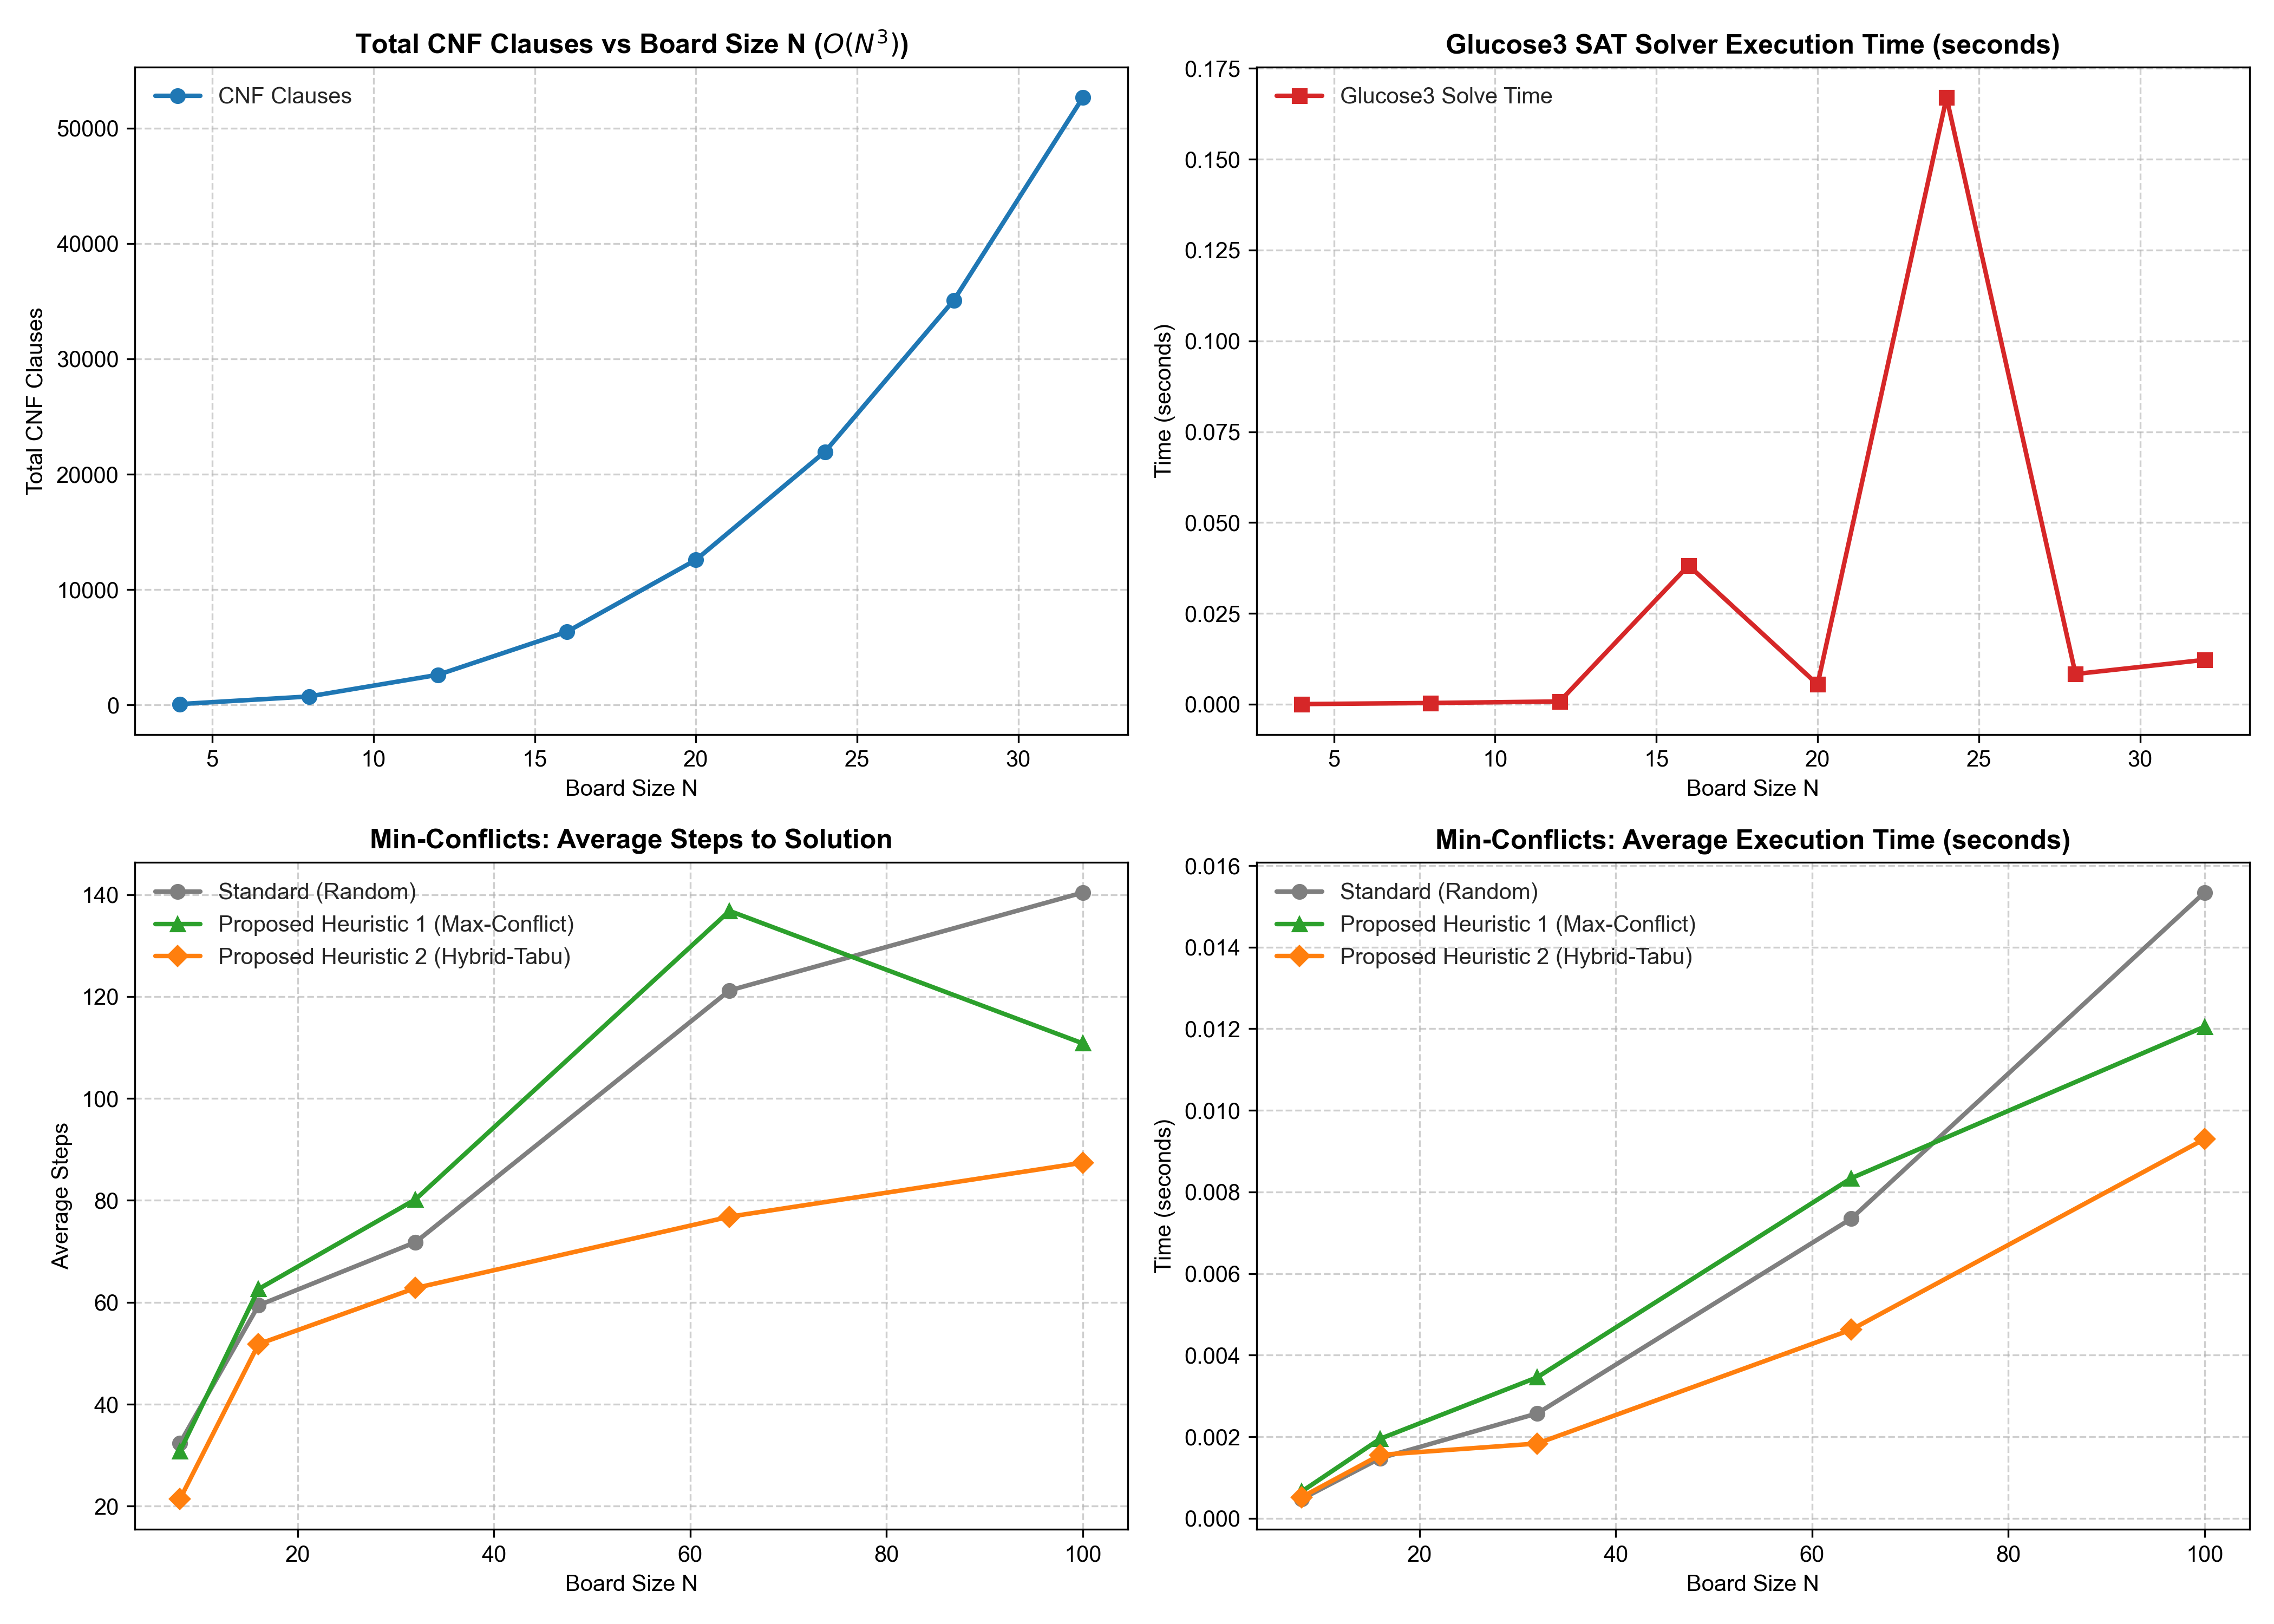

CNF Clause Count Breakdown by Constraint Category:


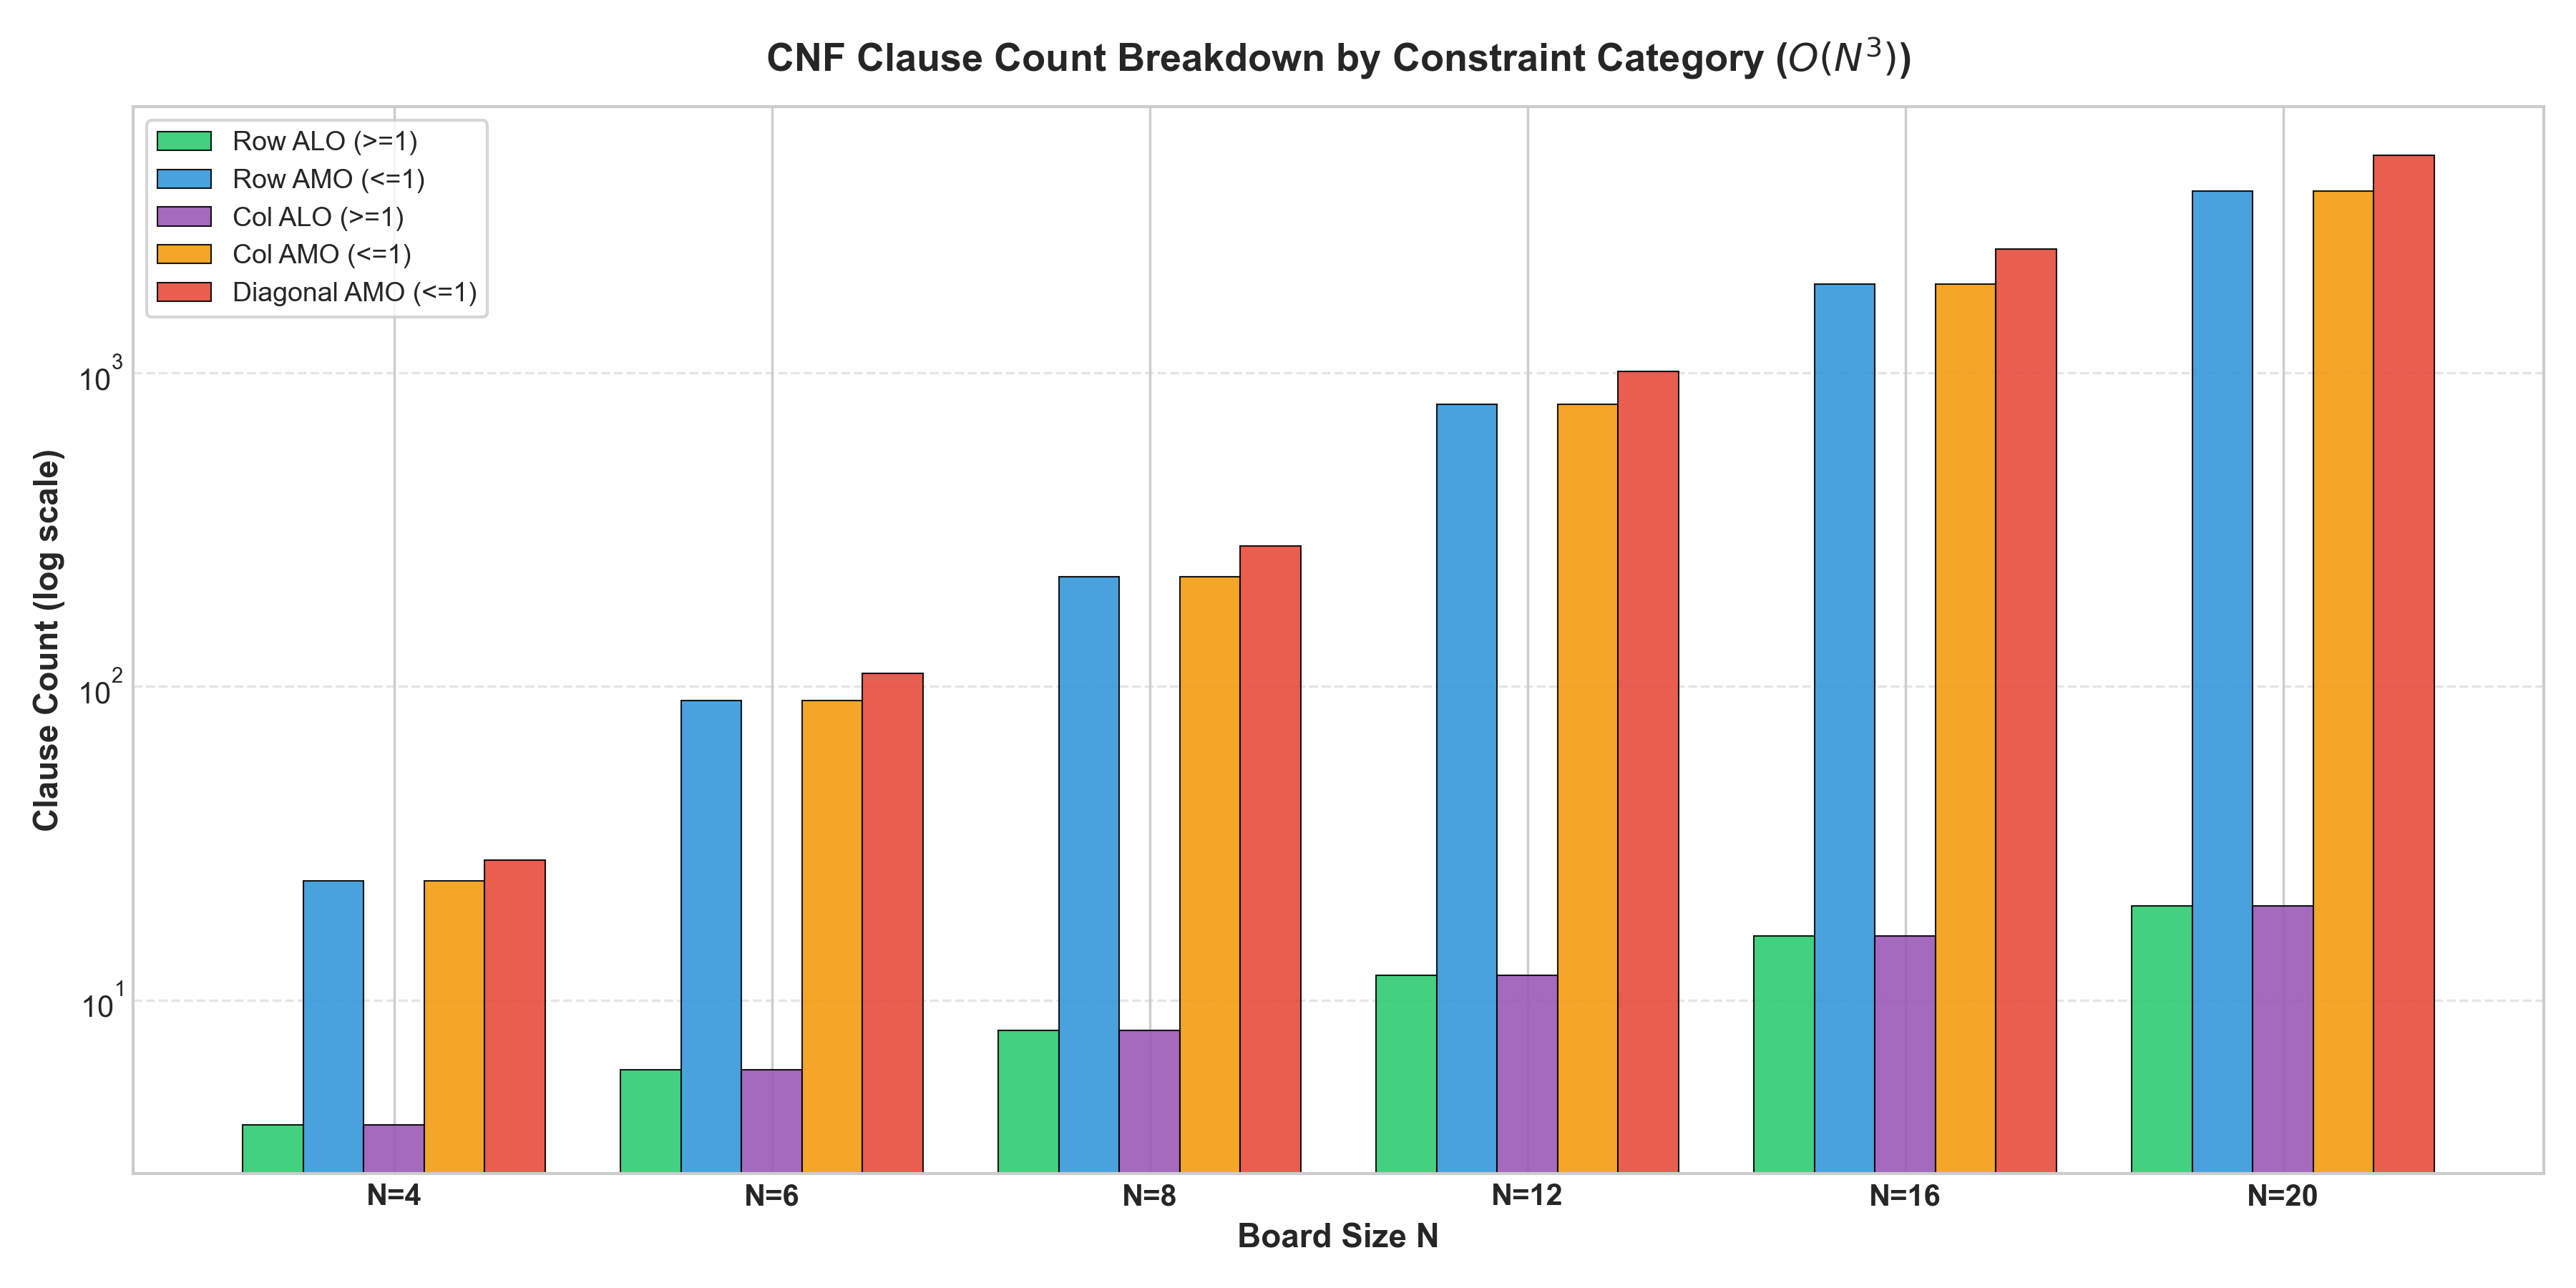

In [5]:
# Display benchmark and CNF breakdown figures directly in notebook
from IPython.display import Image, display

if os.path.exists("benchmark_task1.png"):
    print("Benchmark Comparison Chart (Glucose3 vs Min-Conflicts Heuristics):")
    display(Image(filename="benchmark_task1.png"))

if os.path.exists("cnf_breakdown_task1.png"):
    print("CNF Clause Count Breakdown by Constraint Category:")
    display(Image(filename="cnf_breakdown_task1.png"))
